In [57]:
# Inclusão das bibliotecas usadas no trabalho
import numpy as np
import matplotlib.pyplot as plt

## Implementação do perceptron

In [58]:
class Perceptron:
    def __init__(self, learning_rate=0.01, n_epochs=1000, weight_init="random"):
        self.learning_rate = learning_rate
        self.n_epochs = n_epochs
        self.weights = None
        self.weight_init = weight_init
        self.bias = None
        self.errors_per_epoch = []  # Armazena o erro a cada época

    # Inicializando os pesos de forma customizada

    def _initialize_weights(self, n_features):
        """ Inicializa os pesos de acordo com o método escolhido """
        if self.weight_init == "random":
            self.weights = np.random.rand(n_features)
            self.bias = np.random.rand()
        elif self.weight_init == "zeros":
            self.weights = np.zeros(n_features)
            self.bias = 0
        elif self.weight_init == "normal":
            self.weights = np.random.randn(n_features) * 0.01  # Pequenos valores gaussianos
            self.bias = np.random.randn() * 0.01
        else:
            raise ValueError("Opção inválida para inicialização dos pesos")

    def fit(self, X, y):
        n_samples, n_features = X.shape
        self._initialize_weights(n_features)  # Inicializa os pesos dinamicamente
        self.bias = 0

        for epoch in range(self.n_epochs):
            errors = 0  # Contador de erros por época

            for i in range(n_samples):
                linear_output = np.dot(X[i], self.weights) + self.bias
                y_pred = np.sign(linear_output)

                # Atualização dos pesos se houver erro
                if y_pred != y[i]:
                    self.weights += self.learning_rate * y[i] * X[i]
                    self.bias += self.learning_rate * y[i]
                    errors += 1  # Incrementa erro se classificação errada

            # Armazena a taxa de erro (erros / total de amostras)
            self.errors_per_epoch.append(errors / n_samples)

            # Parada antecipada se não houver erros
            if errors == 0:
                break

        # Após o treinamento, calcular e exibir estatísticas 
        self._print_training_summary(X, y, epoch + 1)   

            # Método para exibir a acurácia e pesos finais
    def _print_training_summary(self, X, y, epochs):
        y_pred = self.predict(X)
        accuracy = np.mean(y_pred == y) * 100
        std_dev = np.std(self.weights)

        print("\n===== Resumo do Treinamento =====")
        print(f"Acurácia no conjunto de treino: {accuracy:.2f}%")
        print(f"Número total de épocas: {epochs}")
        print(f"Pesos finais aprendidos: {self.weights}")
        print(f"Bias final: {self.bias}")
        print("=================================\n")


        # Retorna a predição com base no treinamento do Perceptron
    def predict(self, X):
        return np.sign(np.dot(X, self.weights) + self.bias)

    # Faz previsões e, se os rótulos forem fornecidos, exibe métricas
    # Coloque esse método (não está nos slides)
    def predict2(self, X, y, y_true=None):
        y_pred = np.sign(np.dot(X, self.weights) + self.bias)

        # Se y_true for fornecido, calcular métricas de avaliação
        if y_true is not None:
            self.predict_summary(X, y_true, 0, "Teste")

        return y_pred

        # Calculando as métricas da pedrição
    def predict_summary(self, X, y, epochs, phase):
        """ Método para exibir a acurácia, desvio padrão e pesos finais """
        y_pred = np.sign(np.dot(X, self.weights) + self.bias)
        accuracy = np.mean(y_pred == y) * 100
        std_dev = np.std(self.weights)

        print(f"\n===== Resumo do {phase} =====")
        print(f"Acurácia no conjunto de {phase.lower()}: {accuracy:.2f}%")
        print(f"Desvio Padrão dos Pesos: {std_dev:.5f}")
        if epochs > 0:
            print(f"Número total de épocas: {epochs}")
        print(f"Pesos finais aprendidos: {self.weights}")
        print(f"Bias final: {self.bias}")
        print("=================================\n")

        # Plota o gráfico da evolução dos erros ao longo das épocas de treinamento.
    def plot_error(self):
        plt.figure(figsize=(8, 4))
        plt.plot(self.errors_per_epoch, marker='o', linestyle='-')
        plt.xlabel("Época")
        plt.ylabel("Taxa de erro")
        plt.title("Evolução do erro ao longo das épocas")
        plt.grid()
        plt.show()

In [59]:
# Gráfico da "fronteira" gerado pelo Perceptron
def plot_decision_boundary(X, y, model, title="Fronteira de Decisão do Perceptron"):
    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 100), np.linspace(y_min, y_max, 100))

    # Predição para cada ponto da grade
    Z = model.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)

    # Criar o gráfico
    plt.contourf(xx, yy, Z, alpha=0.3)
    plt.scatter(X[:, 0], X[:, 1], c=y, cmap="bwr", edgecolors="k")
    plt.xlabel("X1")
    plt.ylabel("X2")
    plt.title(title)
    plt.show()

In [60]:
# Função para plotar lado a lado: dataset e fronteira de decisão
def plot_comparison(X, y, model):
    # Criar uma grade para o plano cartesiano
    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 100), np.linspace(y_min, y_max, 100))

    # Predição para cada ponto da grade
    Z = model.predict(np.c_[xx.ravel(), yy.ravel()])
    Z = Z.reshape(xx.shape)

    # Criar os subplots (1 linha, 2 colunas)
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))

    # Subplot 1 - Fronteira de Decisão
    axes[0].contourf(xx, yy, Z, alpha=0.3)
    axes[0].scatter(X[:, 0], X[:, 1], c=y, cmap="bwr", edgecolors="k")
    axes[0].set_xlabel("X1")
    axes[0].set_ylabel("X2")
    axes[0].set_title("Fronteira de Decisão do Perceptron")

    # Subplot 2 - Apenas os Dados
    axes[1].scatter(X[:, 0], X[:, 1], c=y, cmap="bwr", edgecolors="k")
    axes[1].set_xlabel("X1")
    axes[1].set_ylabel("X2")
    axes[1].set_title("Distribuição dos Dados do Dataset")

    plt.tight_layout()
    plt.show()


===== Resumo do Treinamento =====
Acurácia no conjunto de treino: 48.00%
Número total de épocas: 100
Pesos finais aprendidos: [ 0.07847318 -0.06331634]
Bias final: 0.0



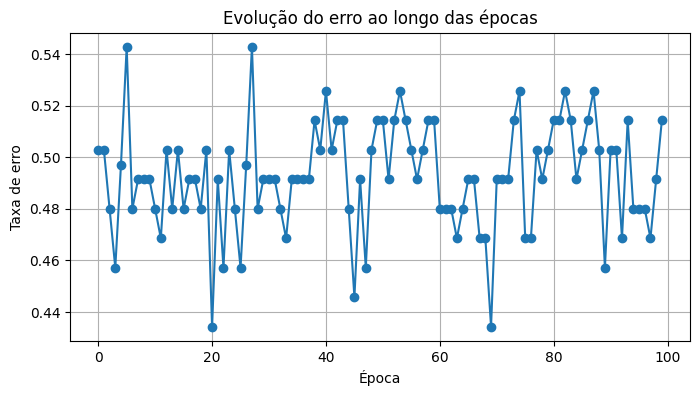

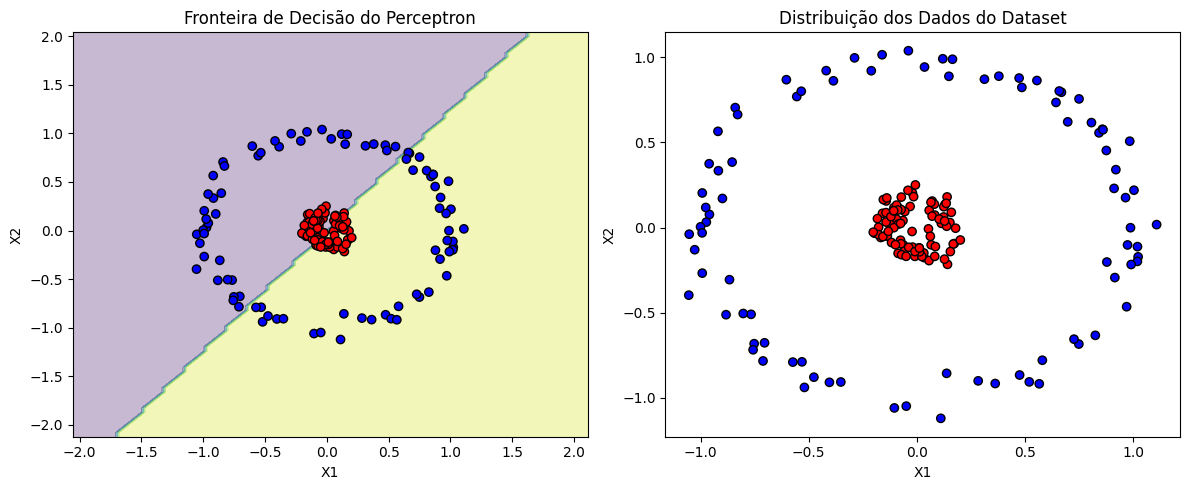

In [61]:
# Dataset 1 - Importando e visualizando o dataset de TREINO
train_dataset1 = np.loadtxt("train_dataset2.csv", delimiter=",", skiprows=1, dtype=float)

# Definição das entradas
X = train_dataset1[:, :2]  # As duas primeiras colunas são os atributos (X1 e X2)
y = train_dataset1[:, 2]  # Terceira coluna (rótulos)

# Converter rótulos para -1 e 1 (caso estejam diferentes)
y = np.where(y == -1, -1, 1)

# Criação do Perceptron e defeinição da taxa de aprendizado como 0.1 e número de épocas em 100
perceptron = Perceptron(learning_rate=0.1, n_epochs=100)

# Treinamento do Perceptron
perceptron.fit(X, y)

# Fazer previsões
y_pred = perceptron.predict2(X, y)

# Plotar a evolução do erro
perceptron.plot_error()

print("")

# Plot dos gráficos lado a lado
plot_comparison(X, y, perceptron)

### Testando os dados do Perceptron com os dados do Dataset 1


===== Resumo do Teste =====
Acurácia no conjunto de teste: 53.33%
Desvio Padrão dos Pesos: 0.07089
Pesos finais aprendidos: [ 0.07847318 -0.06331634]
Bias final: 0.0



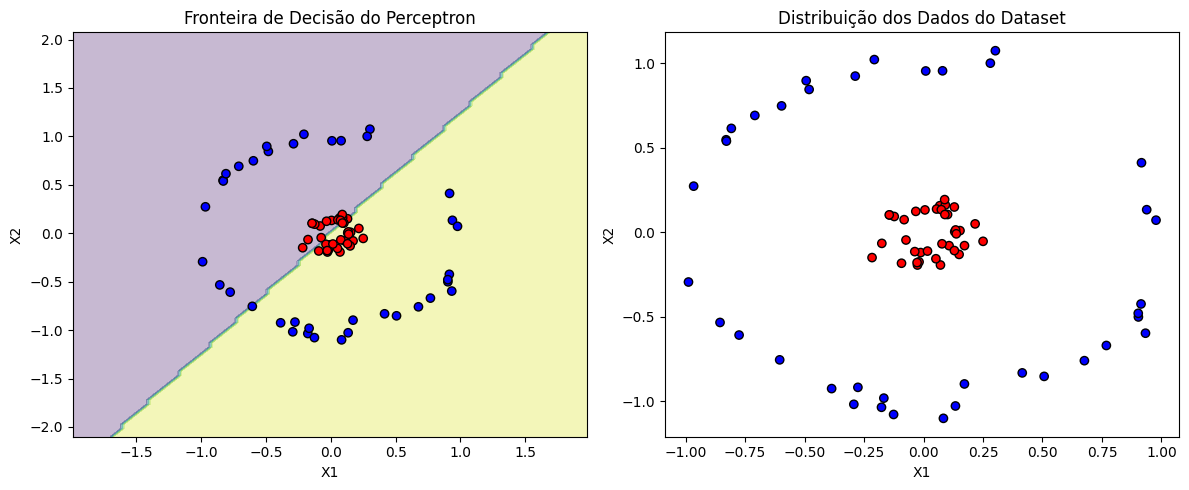

In [62]:
# Dataset 1 - Importando e visualizando o dataset de TESTE
test_dataset1 = np.loadtxt("test_dataset2.csv", delimiter=",", skiprows=1, dtype=float)

# Separar entradas (X1, X2) e rótulos (label) do dataset de teste
X_test = test_dataset1[:, :2]  # Duas primeiras colunas são atributos (X1, X2)
y_test = test_dataset1[:, 2]   # Última coluna é o rótulo
y_test = np.where(y_test == -1, -1, 1)  # Converter rótulos para -1 e 1 (caso estejam diferentes)

# Fazer previsões
perceptron.predict2(X_test, y, y_test)

# Plot dos gráficos lado a lado
plot_comparison(X_test, y_test, perceptron)

Cenário 1 - Tx Treinamento: 0.1 | Épocas 100 

===== Resumo do Treinamento =====
Acurácia no conjunto de treino: 90.48%
Número total de épocas: 100
Pesos finais aprendidos: [-0.13491279 -0.38248769 -0.19360362 -0.17037614  0.09562943 -0.02047303
  0.14360245  0.42186252 -0.1925686   1.21767752]
Bias final: 0.10000000000000003



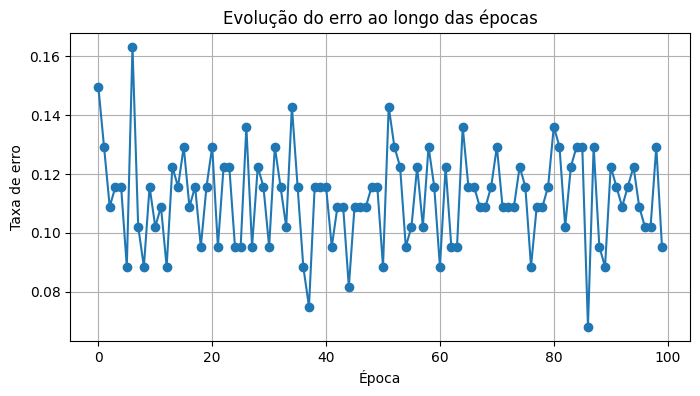


Cenário 2 - Tx Treinamento: 0.1 | Épocas 200 

===== Resumo do Treinamento =====
Acurácia no conjunto de treino: 91.84%
Número total de épocas: 200
Pesos finais aprendidos: [ 0.01890423 -0.17044747 -0.1255729  -0.21460178  0.3287059  -0.07954288
 -0.04495022  0.03202225 -0.09246622  1.14599756]
Bias final: 0.10000000000000003



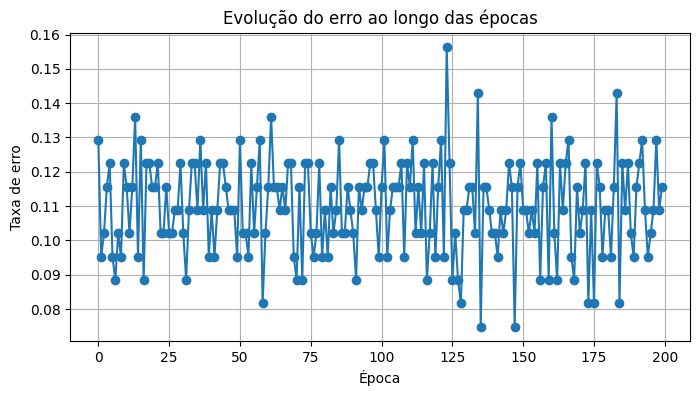


Cenário 3 - Tx Treinamento: 0.001 | Épocas 100 

===== Resumo do Treinamento =====
Acurácia no conjunto de treino: 94.56%
Número total de épocas: 100
Pesos finais aprendidos: [-0.03277778  0.06627885  0.03862947  0.00148462 -0.03355485 -0.06227229
  0.07617189  0.24222566 -0.06941836  0.50199316]
Bias final: -0.07100000000000005



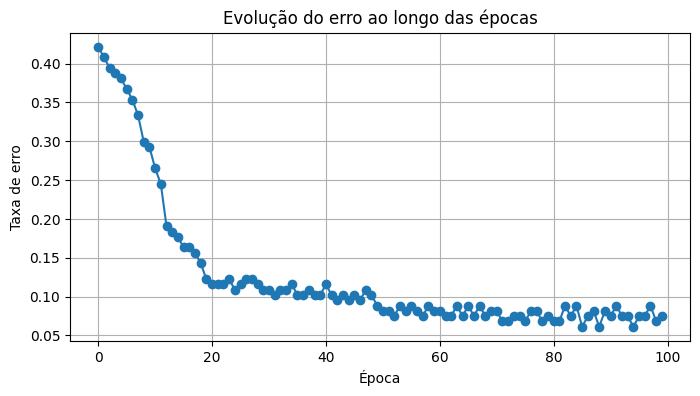


Cenário 4 - Tx Treinamento: 0.001 | Épocas 200 

===== Resumo do Treinamento =====
Acurácia no conjunto de treino: 95.24%
Número total de épocas: 200
Pesos finais aprendidos: [ 0.00644655  0.05607873 -0.07412219 -0.07679001 -0.02467139 -0.03999253
  0.04029045  0.21310272 -0.03723883  0.56877508]
Bias final: 0.040000000000000036



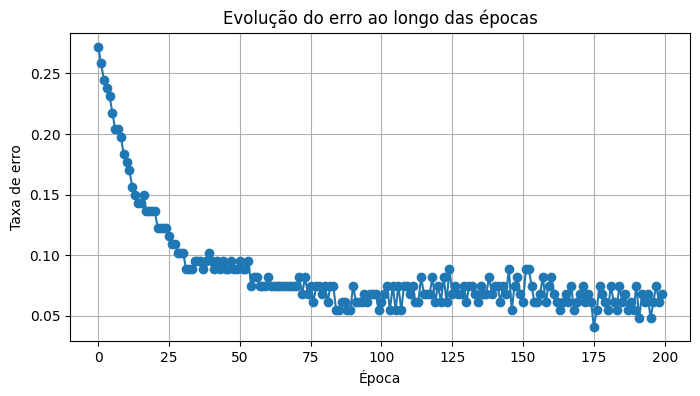


Cenário 5 - Tx Treinamento: 0.0001 | Épocas 100 

===== Resumo do Treinamento =====
Acurácia no conjunto de treino: 74.83%
Número total de épocas: 100
Pesos finais aprendidos: [0.18316811 0.21034064 0.10786856 0.51391973 0.33699631 0.48805255
 0.25456157 0.23654683 0.0563914  0.55067146]
Bias final: -0.07550000000000114



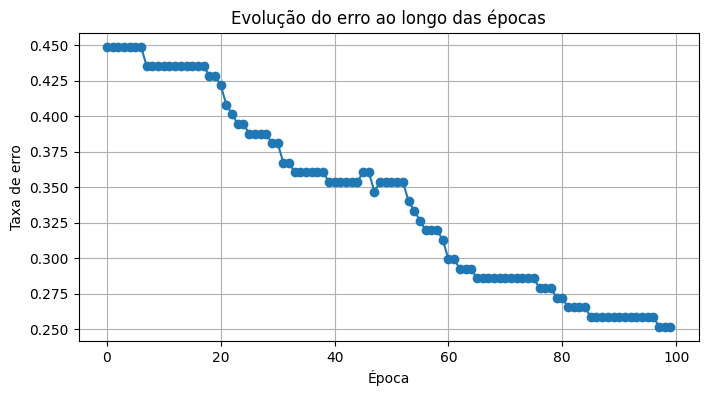


Cenário 6 - Tx Treinamento: 0.0001 | Épocas 200 

===== Resumo do Treinamento =====
Acurácia no conjunto de treino: 82.99%
Número total de épocas: 200
Pesos finais aprendidos: [ 0.07550349 -0.09769623  0.39995383  0.49522511  0.22118676  0.29152943
  0.02142977  0.12615811  0.19918648  0.7522504 ]
Bias final: -0.1591999999999988



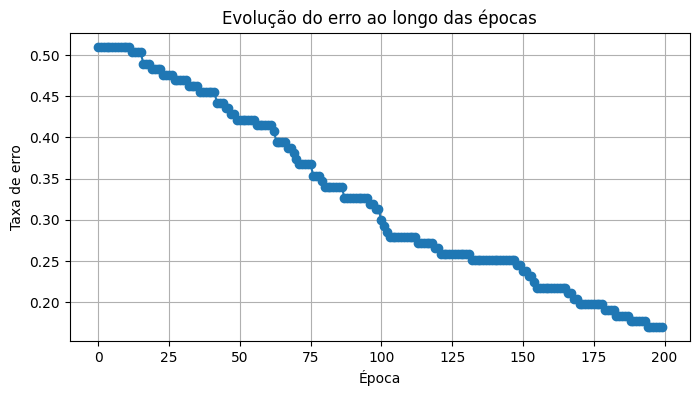

In [63]:
# Dataset 3 - Importando e visualizando o dataset de TREINO
train_dataset3 = np.loadtxt("train_dataset3.csv", delimiter=",", skiprows=1, dtype=float) 

# Definição das entradas
X = train_dataset3[:, :-1]  # Todas as colunas, exceto a última (10 features)
y = train_dataset3[:, -1]   # Última coluna é o rótulo
y = np.where(y == -1, -1, 1)  # Converter rótulos para -1 e 1 (caso estejam diferentes)

# Criação do Perceptron de acordo com os cenários da tabela 
perceptron_cenario_1 = Perceptron(learning_rate=0.1, n_epochs=100)
perceptron_cenario_2 = Perceptron(learning_rate=0.1, n_epochs=200)
perceptron_cenario_3 = Perceptron(learning_rate=0.001, n_epochs=100)
perceptron_cenario_4 = Perceptron(learning_rate=0.001, n_epochs=200)
perceptron_cenario_5 = Perceptron(learning_rate=0.0001, n_epochs=100)
perceptron_cenario_6 = Perceptron(learning_rate=0.0001, n_epochs=200)

print("Cenário 1 - Tx Treinamento: 0.1 | Épocas 100 ")

# Treinamento do Perceptron
perceptron_cenario_1.fit(X, y)

# Plotar a evolução do erro
perceptron_cenario_1.plot_error()
print("")

# ------------------------------------

print("Cenário 2 - Tx Treinamento: 0.1 | Épocas 200 ")

# Treinamento do Perceptron
perceptron_cenario_2.fit(X, y)

# Plotar a evolução do erro
perceptron_cenario_2.plot_error()
print("")

# ------------------------------------

print("Cenário 3 - Tx Treinamento: 0.001 | Épocas 100 ")

# Treinamento do Perceptron
perceptron_cenario_3.fit(X, y)

# Plotar a evolução do erro
perceptron_cenario_3.plot_error()
print("")

# ------------------------------------

print("Cenário 4 - Tx Treinamento: 0.001 | Épocas 200 ")

# Treinamento do Perceptron
perceptron_cenario_4.fit(X, y)

# Plotar a evolução do erro
perceptron_cenario_4.plot_error()
print("")

# ------------------------------------

print("Cenário 5 - Tx Treinamento: 0.0001 | Épocas 100 ")

# Treinamento do Perceptron
perceptron_cenario_5.fit(X, y)

# Plotar a evolução do erro
perceptron_cenario_5.plot_error()
print("")

# ------------------------------------

print("Cenário 6 - Tx Treinamento: 0.0001 | Épocas 200 ")

# Treinamento do Perceptron
perceptron_cenario_6.fit(X, y)

# Plotar a evolução do erro
perceptron_cenario_6.plot_error()
print("")

In [64]:
test_dataset3 = np.loadtxt("test_dataset3.csv", delimiter=",", skiprows=1, dtype=float)

# Definição das entradas
X_test = test_dataset3[:, :-1]   # Todas as colunas, exceto a última (10 features)
y_test = test_dataset3[:, -1]    # Última coluna é o rótulo
y_test = np.where(y_test == -1, -1, 1) # Converter rótulos para -1 e 1 (caso estejam diferentes)

# Fazer previsões de acordo com os cenários

# ---------------------------------------------
# Cenário 1
print("Cenário 1 - Tx Treinamento: 0.1 | Épocas 100 ")
perceptron_cenario_1.predict2(X_test, y, y_test)
print("")

Cenário 1 - Tx Treinamento: 0.1 | Épocas 100 

===== Resumo do Teste =====
Acurácia no conjunto de teste: 80.95%
Desvio Padrão dos Pesos: 0.43560
Pesos finais aprendidos: [-0.13491279 -0.38248769 -0.19360362 -0.17037614  0.09562943 -0.02047303
  0.14360245  0.42186252 -0.1925686   1.21767752]
Bias final: 0.10000000000000003




In [65]:
# ---------------------------------------------
# Cenário 2
print("Cenário 2 - Tx Treinamento: 0.1 | Épocas 200 ")
perceptron_cenario_2.predict2(X_test, y, y_test)

Cenário 2 - Tx Treinamento: 0.1 | Épocas 200 

===== Resumo do Teste =====
Acurácia no conjunto de teste: 88.89%
Desvio Padrão dos Pesos: 0.38299
Pesos finais aprendidos: [ 0.01890423 -0.17044747 -0.1255729  -0.21460178  0.3287059  -0.07954288
 -0.04495022  0.03202225 -0.09246622  1.14599756]
Bias final: 0.10000000000000003



array([-1., -1.,  1.,  1., -1.,  1., -1., -1.,  1.,  1., -1., -1., -1.,
       -1., -1.,  1.,  1., -1.,  1., -1.,  1.,  1.,  1., -1., -1., -1.,
        1.,  1., -1.,  1.,  1.,  1., -1., -1., -1.,  1., -1., -1., -1.,
        1.,  1., -1., -1.,  1.,  1.,  1., -1., -1., -1.,  1.,  1.,  1.,
        1., -1.,  1.,  1.,  1.,  1.,  1., -1., -1., -1., -1.])

In [66]:
# ---------------------------------------------
# Cenário 3
print("Cenário 3 - Tx Treinamento: 0.001 | Épocas 100 ")
perceptron_cenario_3.predict2(X_test, y, y_test)

Cenário 3 - Tx Treinamento: 0.001 | Épocas 100 

===== Resumo do Teste =====
Acurácia no conjunto de teste: 79.37%
Desvio Padrão dos Pesos: 0.16738
Pesos finais aprendidos: [-0.03277778  0.06627885  0.03862947  0.00148462 -0.03355485 -0.06227229
  0.07617189  0.24222566 -0.06941836  0.50199316]
Bias final: -0.07100000000000005



array([-1., -1.,  1.,  1., -1.,  1.,  1., -1.,  1.,  1., -1., -1., -1.,
       -1., -1.,  1.,  1., -1.,  1., -1., -1., -1.,  1., -1., -1., -1.,
        1., -1., -1.,  1.,  1.,  1., -1., -1., -1.,  1., -1., -1.,  1.,
        1.,  1., -1.,  1.,  1.,  1.,  1.,  1.,  1., -1.,  1.,  1.,  1.,
        1., -1., -1.,  1.,  1.,  1., -1., -1., -1., -1., -1.])

In [67]:
# ---------------------------------------------
# Cenário 4
print("Cenário 4 - Tx Treinamento: 0.001 | Épocas 200 ")
perceptron_cenario_4.predict2(X_test, y, y_test)

Cenário 4 - Tx Treinamento: 0.001 | Épocas 200 

===== Resumo do Teste =====
Acurácia no conjunto de teste: 85.71%
Desvio Padrão dos Pesos: 0.18676
Pesos finais aprendidos: [ 0.00644655  0.05607873 -0.07412219 -0.07679001 -0.02467139 -0.03999253
  0.04029045  0.21310272 -0.03723883  0.56877508]
Bias final: 0.040000000000000036



array([-1.,  1.,  1.,  1., -1.,  1., -1., -1.,  1.,  1., -1., -1., -1.,
       -1., -1.,  1.,  1., -1.,  1., -1.,  1.,  1.,  1., -1., -1., -1.,
        1., -1., -1.,  1.,  1.,  1., -1., -1., -1.,  1.,  1., -1.,  1.,
        1.,  1., -1.,  1.,  1.,  1.,  1.,  1., -1., -1.,  1.,  1.,  1.,
        1., -1.,  1.,  1.,  1.,  1.,  1., -1., -1., -1., -1.])

In [68]:
# ---------------------------------------------
# Cenário 5
print("Cenário 5 - Tx Treinamento: 0.0001 | Épocas 100 ")
perceptron_cenario_5.predict2(X_test, y, y_test)

Cenário 5 - Tx Treinamento: 0.0001 | Épocas 100 

===== Resumo do Teste =====
Acurácia no conjunto de teste: 71.43%
Desvio Padrão dos Pesos: 0.16401
Pesos finais aprendidos: [0.18316811 0.21034064 0.10786856 0.51391973 0.33699631 0.48805255
 0.25456157 0.23654683 0.0563914  0.55067146]
Bias final: -0.07550000000000114



array([-1., -1., -1.,  1.,  1.,  1.,  1., -1.,  1., -1., -1., -1., -1.,
       -1., -1.,  1.,  1., -1., -1., -1.,  1.,  1.,  1., -1., -1., -1.,
        1., -1., -1.,  1.,  1.,  1.,  1., -1., -1.,  1., -1., -1.,  1.,
        1.,  1., -1.,  1.,  1.,  1.,  1., -1.,  1.,  1.,  1.,  1.,  1.,
        1., -1.,  1.,  1., -1.,  1., -1., -1.,  1., -1.,  1.])

In [69]:
# ---------------------------------------------
# Cenário 6
print("Cenário 6 - Tx Treinamento: 0.0001 | Épocas 200 ")
perceptron_cenario_6.predict2(X_test, y, y_test)

Cenário 6 - Tx Treinamento: 0.0001 | Épocas 200 

===== Resumo do Teste =====
Acurácia no conjunto de teste: 71.43%
Desvio Padrão dos Pesos: 0.23641
Pesos finais aprendidos: [ 0.07550349 -0.09769623  0.39995383  0.49522511  0.22118676  0.29152943
  0.02142977  0.12615811  0.19918648  0.7522504 ]
Bias final: -0.1591999999999988



array([-1., -1., -1.,  1., -1.,  1.,  1., -1.,  1., -1., -1., -1., -1.,
       -1., -1.,  1.,  1., -1.,  1., -1.,  1.,  1.,  1., -1., -1.,  1.,
        1., -1., -1.,  1.,  1.,  1.,  1., -1., -1.,  1., -1., -1.,  1.,
        1.,  1., -1.,  1.,  1.,  1.,  1., -1.,  1.,  1.,  1.,  1.,  1.,
       -1., -1.,  1.,  1., -1.,  1., -1.,  1.,  1., -1., -1.])